## 04 Analysis of Results in Tarifverbund Schwyz

In [1]:
import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np

stop_places = gpd.read_file(
    '../data/stop-places-schwyz/stop-places-schwyz-with-buffers.gpkg', 
    layer = 'stop_buffers',
    columns = ['Name', 'Nummer', 'buffer_timeseries', 'geometry']
)

stop_places.head()

,Name,Nummer,buffer_timeseries,geometry
0,"Vitznau, Unterwilen",8577219,"[{""time"": ""2026-04-15T02:51:00Z"", ""buffer"": 52...",POINT (2678424 1208199)
1,"Weggis, Lützelau",8592427,"[{""time"": ""2026-04-15T02:52:00Z"", ""buffer"": 52...",POINT (2677775 1208686)
2,"Weggis, Lorbeerweg",8595630,NO TRANSFERS,POINT (2677367 1208708)
3,Gersau (See),8508468,NO TRANSFERS,POINT (2682717 1204972)
4,"Gersau, Schiffstation",8505671,"[{""time"": ""2026-04-15T02:54:00Z"", ""buffer"": 26...",POINT (2682727 1204989)


Total Stops: 51
Stops without Service: 4
Stops without Transfer: 23
Stops with Possible Transfers: 24


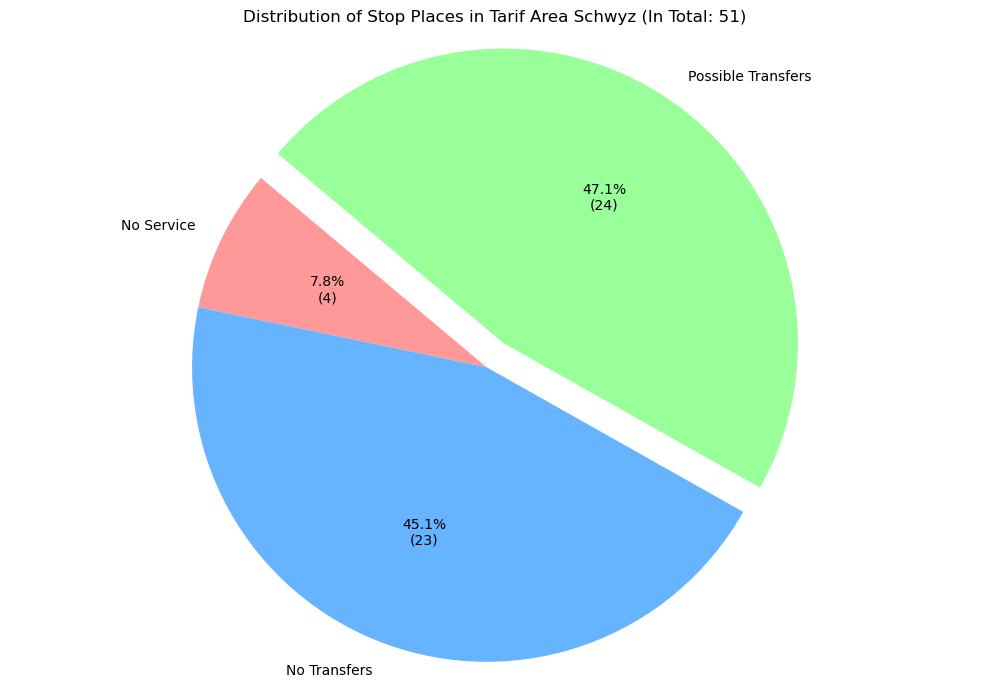

In [4]:
# Stats for stops without service, transfers and stops with possible transfers
total_stops = len(stop_places)
stops_without_service = len(stop_places[stop_places['buffer_timeseries']=='NO SERVICE'])
stops_without_transfer = len(stop_places[stop_places['buffer_timeseries']=='NO TRANSFERS'])
stops_with_transfers = total_stops - stops_without_service - stops_without_transfer

# Print the results
print(f"Total Stops: {total_stops}")
print(f"Stops without Service: {stops_without_service}")
print(f"Stops without Transfer: {stops_without_transfer}")
print(f"Stops with Possible Transfers: {stops_with_transfers}")

# Create labels and sizes for the pie chart
labels = ['No Service', 'No Transfers', 'Possible Transfers']
sizes = [stops_without_service, stops_without_transfer, stops_with_transfers]
colors = ['#ff9999','#66b3ff','#99ff99'] # Light red, blue, and green
explode = (0, 0, 0.1)  # "explode" the first slice (No Service)

# Function to format the labels to show both count and percentage
def label_format(pct, allvals):
    absolute = int(round(pct/100.* np.sum(allvals)))
    return f"{pct:.1f}%\n({absolute:d})"

# Create the pie chart
plt.figure(figsize=(10, 7))
plt.pie(sizes, 
        explode=explode, 
        labels=labels, 
        colors=colors, 
        autopct=lambda pct: label_format(pct, sizes), 
        startangle=140)

plt.title(f'Distribution of Stop Places in Tarif Area Schwyz (In Total: {total_stops})')
plt.axis('equal')
plt.tight_layout()
# plt.savefig('stops_statistics_pie_chart.png')
plt.show()

In [5]:
stop_places_active = stop_places[
    (stop_places['buffer_timeseries'] != 'NO SERVICE') & 
    (stop_places['buffer_timeseries'] != 'NO TRANSFERS')
].copy()
stop_places_active.reset_index(drop=True, inplace=True)

print(stop_places_active.head())

                    Name   Nummer  \
0    Vitznau, Unterwilen  8577219   
1       Weggis, Lützelau  8592427   
2  Gersau, Schiffstation  8505671   
3        Gersau, Förstli  8577224   
4       Gersau, Rotschuo  8505666   

                                   buffer_timeseries                 geometry  
0  [{"time": "2026-04-15T02:51:00Z", "buffer": 52...  POINT (2678424 1208199)  
1  [{"time": "2026-04-15T02:52:00Z", "buffer": 52...  POINT (2677775 1208686)  
2  [{"time": "2026-04-15T02:54:00Z", "buffer": 26...  POINT (2682727 1204989)  
3  [{"time": "2026-04-15T03:33:00Z", "buffer": 50...  POINT (2681035 1205140)  
4  [{"time": "2026-04-15T03:35:00Z", "buffer": 50...  POINT (2679788 1205297)  
